# Gate 2 — DPP4 curation and the evaluation boundary

Human DPP4 is locked: **CHEMBL284**, frozen ChEMBL_37 pull. This notebook rebuilds the
seven-step cascade, splits and **one fixed leakage probe** from saved raw data, offline.
No Gate 3 baseline or Gate 4 model is fitted. Literature/patent IC50 measurements do
not establish efficacy, safety or suitability of any compound.

Select the repo's `.venv` Python kernel and **Restart & Run All**, or run from the repo:

```bash
.venv/bin/python scripts/run_gate2_notebook.py
```

The script executes every code cell in order without opening a kernel listener and
saves outputs in this notebook. Derived data go to a temporary directory, leaving
committed data/results untouched. Final assertions compare regenerated outputs with
committed results and recheck every raw file, including the manifest. The production
command remains `./run_all.sh`. All displayed numbers come from this execution.

In [1]:
from pathlib import Path
from collections import Counter
from tempfile import TemporaryDirectory
from hashlib import sha256
import io
import json
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "curate.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "data/raw/CHEMBL284/manifest.json").is_file(), "Start in the repo or notebooks/"
assert Path(sys.executable).resolve() == (ROOT / ".venv/bin/python").resolve(), "Use .venv Python"
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import SEED, set_global_seed
from src.retrieve import verify_raw, read_jsonl_gz
from src.curate import curate_target, new_figure
from src.splits import split_target
from src.leakage_probe import run_probe

set_global_seed()
RAW = ROOT / "data/raw/CHEMBL284"
assert verify_raw(RAW), "Frozen raw checksum mismatch"
def raw_hashes():
    return {p.name: sha256(p.read_bytes()).hexdigest()
            for p in RAW.iterdir() if p.is_file() and not p.name.startswith("._")}
raw_before = raw_hashes()
workspace = TemporaryDirectory(prefix="qsar-gate2-")
WORK = Path(workspace.name)
CURATED, CURATION, SPLITS, PROBE = [WORK / n for n in ("curated", "curation", "splits", "probe")]

def show_figure(fig):
    with io.BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    fig.clear()

print(f"Target CHEMBL284; seed {SEED}; frozen raw checksums verified.")

Target CHEMBL284; seed 42; frozen raw checksums verified.


## Seven decisions, seven logged steps

Binding assays → IC50 → human target → positive finite molar values expressed in nM
→ exact `=` relations → sanitise, largest fragment, neutralise, canonical SMILES,
InChIKey → median pIC50 per full standardised InChIKey. The last count changes from
**records to compounds**. Parent and molecule IDs remain audit columns; salt forms
must not enter the split as separate compounds. Stereoisomers retain different full keys.

,step,records_in,records_out,records_removed
0,1_binding_assay,8397,8174,223
1,2_single_activity_type,8174,5781,2393
2,3_single_target_organism,5781,5781,0
3,4_units_harmonised_to_nM,5781,5650,131
4,5_censored_removed,5650,4859,791
5,6_structure_standardised,4859,4855,4
6,7_duplicates_resolved,4855,3965,890


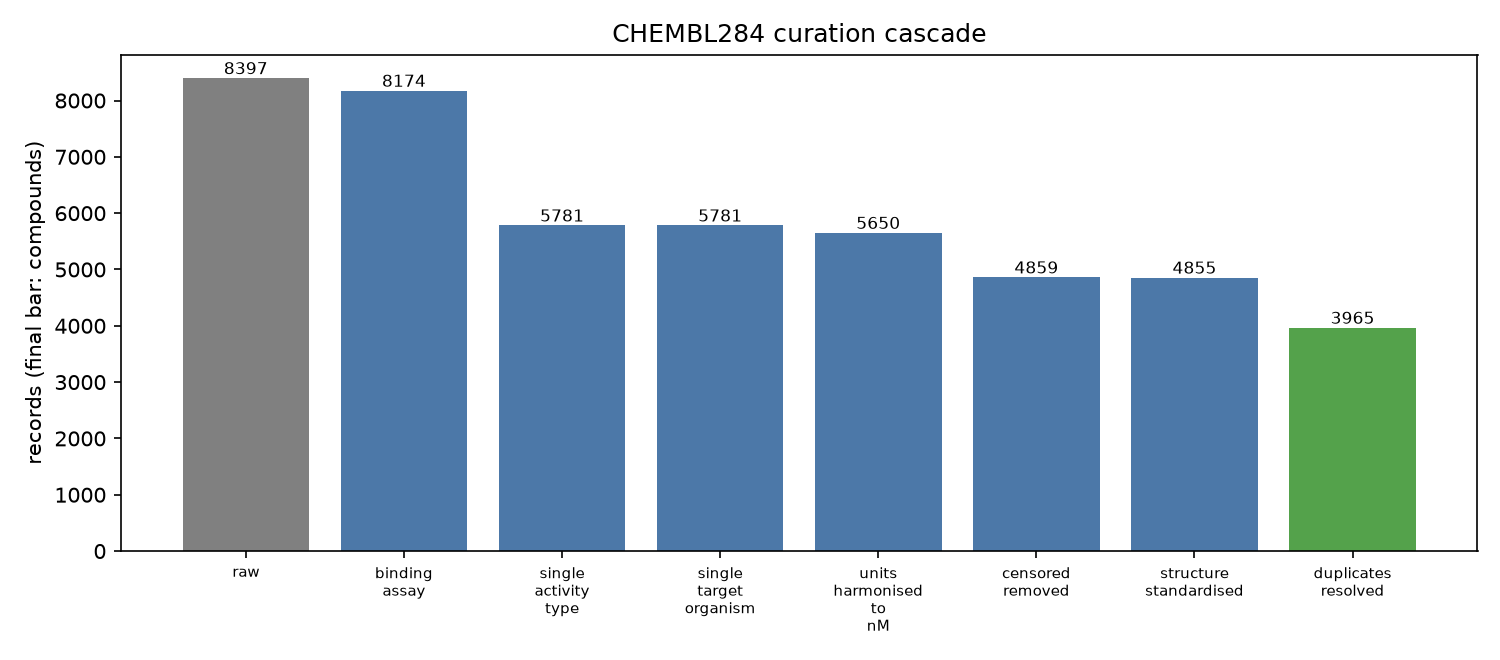

Gate 1's **796** non-exact rows reconcile with **791** censored rows here: **5** null-value/null-relation rows leave at the value check. No censored measurement is treated differently by the two gates. The 791/796 gap is five value-less rows removed one step earlier here, and the 4859 rows that survive the relation rule are identical in both.

**units_refused.csv**: 131 itemised rows (first five below).

,activity_id,standard_units,units_as_reported,standard_value,reason
0,473917,ug.mL-1,ug ml-1,23.4,no unambiguous molar conversion
1,473923,ug.mL-1,ug ml-1,12.0,no unambiguous molar conversion
2,478635,ug.mL-1,ug ml-1,21.3,no unambiguous molar conversion
3,483596,ug.mL-1,ug ml-1,100.0,no unambiguous molar conversion
4,487078,ug.mL-1,ug ml-1,16.0,no unambiguous molar conversion


**structure_failures.csv**: 4 itemised rows (first five below).

,activity_id,molecule_chembl_id,canonical_smiles_in,failure
0,15010453,CHEMBL3310989,NaN,missing_smiles: no canonical_smiles in the API...
1,17610921,CHEMBL3648425,NaN,missing_smiles: no canonical_smiles in the API...
2,17610922,CHEMBL4115755,NaN,missing_smiles: no canonical_smiles in the API...
3,17610923,CHEMBL3648424,NaN,missing_smiles: no canonical_smiles in the API...


In [2]:
curation = curate_target(RAW, CURATED, CURATION)
display(pd.DataFrame(curation["steps"])[["step", "records_in", "records_out", "records_removed"]])
display(Image(filename=str(CURATION / "cascade_funnel.png")))
reconciliation = curation["censoring_reconciliation"]
display(Markdown(
    f"Gate 1's **{reconciliation['gate1_rows_failing_exact_relation_recomputed']}** non-exact rows "
    f"reconcile with **{reconciliation['gate2_step5_censored_rows_removed']}** censored rows here: "
    f"**{reconciliation['difference']}** null-value/null-relation rows leave at the value check. "
    + reconciliation["conclusion"]))
for filename in ("units_refused.csv", "structure_failures.csv"):
    frame = pd.read_csv(CURATION / filename)
    display(Markdown(f"**{filename}**: {len(frame)} itemised rows (first five below)."))
    display(frame.head())

## Identity, repeated reporting and source regimes

Median aggregation prevents an often-reported reference compound from receiving the
weight of an entire analogue series. It does not resolve contradictory measurements:
all spreads remain visible and groups above one log unit remain flagged, not discarded.
`src_id=37` is **BindingDB Patent Bioactivity Data**, established by the saved source
metadata in `results/sources/CHEMBL284/`. These measurements are retained with their
source IDs because they match the endpoint and target; patent and literature regimes
may differ. Supplied validity comments are retained, rather than silently adding a filter.

In [3]:
compounds = pd.read_csv(CURATED / "compounds.csv")
records = pd.read_csv(CURATED / "records_curated.csv")
identity = curation["identity_decisions"]
display(pd.Series({key: identity[key] for key in (
    "distinct_molecule_ids_in_curated_records", "distinct_parent_ids_in_curated_records",
    "compounds_merging_more_than_one_molecule_id", "rows_with_parent_different_from_molecule_id"
)}, name="Observed identity audit").to_frame())
raw_records = read_jsonl_gz(RAW / "activities.jsonl.gz")
busiest_id, raw_count = Counter(r["molecule_chembl_id"] for r in raw_records).most_common(1)[0]
surviving = records.loc[records.molecule_chembl_id == busiest_id]
display(Markdown(
    f"The Gate 1 molecule with **{raw_count}** raw records is **{busiest_id}**. "
    f"It contributes **{len(surviving)}** accepted records to "
    f"**{surviving.inchikey.nunique()}** standardised compound(s). "
    "Its other raw records fail the endpoint/assay/unit/relation/structure rules above; "
    "raw frequency alone is not the number of comparable repeats."))
display(pd.DataFrame([identity["busiest_compound"]]))
display(records.groupby("src_id").size().rename("Curated records by source").to_frame())
display(pd.Series(identity["data_validity_comments"], name="Retained validity comments").to_frame())

,Observed identity audit
distinct_molecule_ids_in_curated_records,4000
distinct_parent_ids_in_curated_records,3965
compounds_merging_more_than_one_molecule_id,32
rows_with_parent_different_from_molecule_id,855


The Gate 1 molecule with **96** raw records is **CHEMBL1422**. It contributes **63** accepted records to **1** standardised compound(s). Its other raw records fail the endpoint/assay/unit/relation/structure rules above; raw frequency alone is not the number of comparable repeats.

,inchikey,molecule_chembl_ids,n_records,n_assays,n_documents,pIC50_median,pIC50_spread,decision
0,MFFMDFFZMYYVKS-SECBINFHSA-N,CHEMBL1201174;CHEMBL1422;CHEMBL393336;CHEMBL53...,71,70,62,7.744727,4.139662,kept as ONE compound with the median of its re...


,Curated records by source
src_id,
1,4333
37,522


,Retained validity comments
<none>,4669
Outside typical range,133
Potential transcription error,53


## Target variable and visible limitations

For each accepted record, $pIC50=9-\log_{10}(IC50_{nM})$; the compound target is its
median across reports. Review the tails and round-number counts before interpreting
an error metric. Low values and high-spread compounds are retained and reported.
Removing explicit bounds prevents substituting assay limits for exact values; it also
selects the observed distribution. Absence of a pile-up among accepted values cannot
prove absence of assay ceilings in the source experiments.

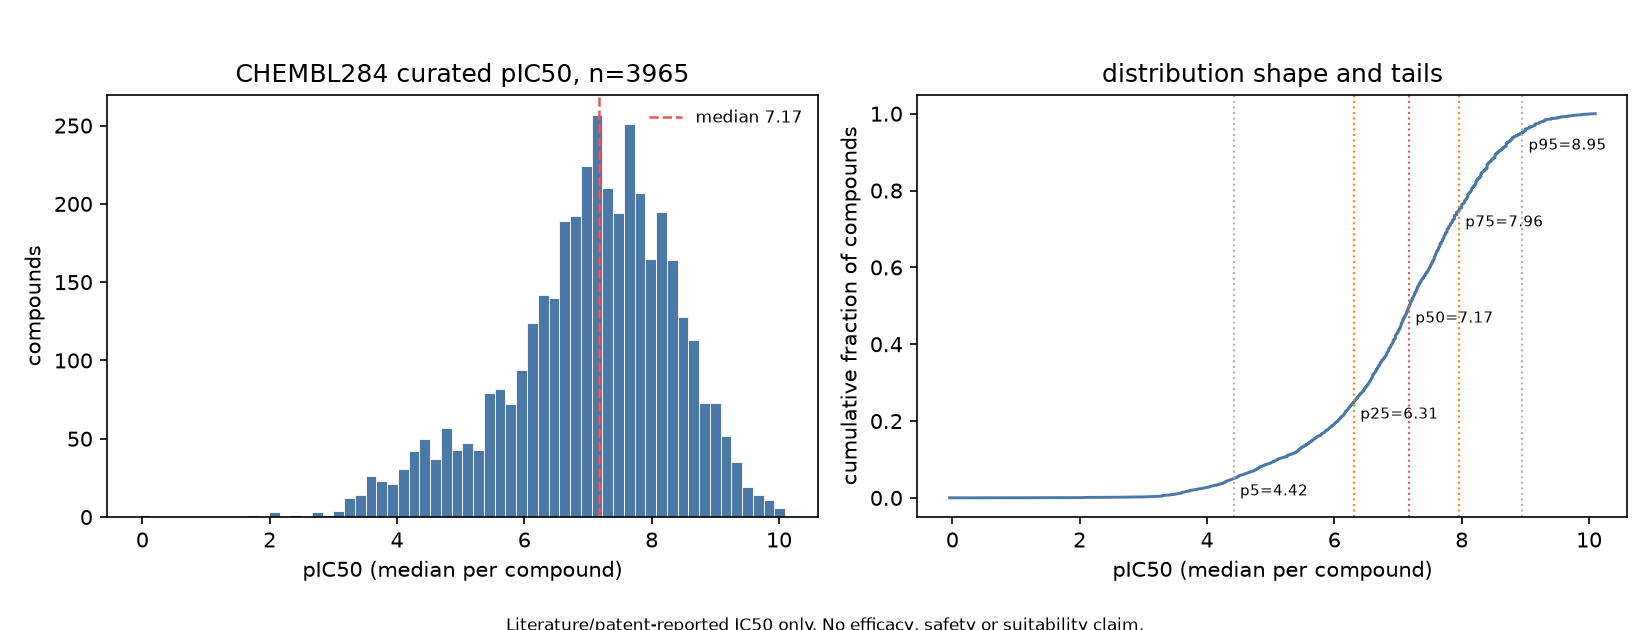

,Compound-median pIC50
n_compounds,3965.000000
min,-0.041393
p05,4.420216
median,7.174361
mean,7.030325
stdev,1.329082
p95,8.950782
max,10.096910
below_2_implausible,2.000000
below_4,108.000000


,Exact integer pIC50 counts
3.0,1
4.0,1
5.0,3
6.0,4
7.0,12
8.0,33
9.0,23
10.0,3


,inchikey,molecule_chembl_ids,pIC50_median,n_records,pIC50_spread
635,FCIDEQNVBVMFSV-RYUDHWBXSA-N,CHEMBL5837755,1.693146,1,0.000000
1557,KNVUDUILISDHBC-OAHLLOKOSA-N,CHEMBL4113723,10.096910,3,1.447158
2374,PIBSTXXPCGKTNL-UHFFFAOYSA-N,CHEMBL5276961,-0.041393,1,0.000000
3412,WQOLTTZVROOXIF-BURHJUHKSA-N,CHEMBL5269668,10.045757,1,0.000000
3696,YNDVTDKMXMMQIW-CQSZACIVSA-N,CHEMBL5914058,10.096910,1,0.000000


In [4]:
display(Image(filename=str(CURATION / "pic50_distribution.png")))
target = curation["target_variable"]
display(pd.Series({k: target[k] for k in (
    "n_compounds", "min", "p05", "median", "mean", "stdev", "p95", "max",
    "below_2_implausible", "below_4", "above_9", "above_10"
)}, name="Compound-median pIC50").to_frame())
display(pd.Series(target["exact_integer_pIC50_values"], name="Exact integer pIC50 counts").to_frame())
display(compounds.loc[(compounds.pIC50_median < 2) | (compounds.pIC50_median > 10),
    ["inchikey", "molecule_chembl_ids", "pIC50_median", "n_records", "pIC50_spread"]])

## Measured repeat dispersion, with the selection made explicit

The pooled within-compound SD is
$\sqrt{\sum_i (n_i-1)s_i^2 / \sum_i(n_i-1)}$, in pIC50 log units.
We recompute it from accepted **individual reports**, not compound medians. Each
repeated compound contributes $n_i-1$ degrees of freedom. Also show the RMS deviation
of reports from their own compound median; it uses a different denominator/centre.

The existing report recommends the subset with differing values and spread ≤1 log
unit. That selection excludes the most contradictory groups. **It is conditional
repeat dispersion, not a universal lower bound on future test RMSE.** Equal reports
could be copied reports or independent agreements; unequal reports need not be
independent experiments. Report all groups and sensitivities together. The choice
of a Gate 4 reference remains open in `DATA_CARD.md`; no escape threshold is fixed here.

RMS deviation from own median (repeated groups only): 0.697 log units
Repeated compounds: 476/3965; spread >1 log unit: 108


,Groups,Degrees of freedom,Pooled SD (log units)
Subset,,,
All repeated groups,476,890,0.827840
Differing groups,254,597,1.010774
"Differing, spread <=1",146,208,0.309841


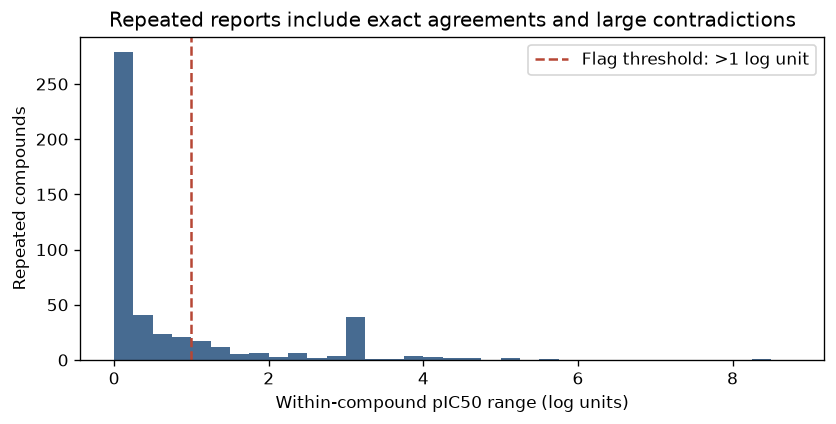

In [5]:
repeated = compounds.loc[compounds.n_records > 1]
report_groups = records.groupby("inchikey").pIC50
stats = report_groups.agg(["count", "std", "min", "max"])
stats = stats.loc[stats["count"] > 1].copy()
stats["spread"] = stats["max"] - stats["min"]
noise = curation["replicate_noise"]
# Match the report's numerical-equality tolerance (0.01 log unit).
subsets = {
    "All repeated groups": (stats, "pooled_within_compound_sd_all_groups"),
    "Differing groups": (stats.loc[stats.spread >= 0.01], "pooled_within_compound_sd_differing_groups"),
    "Differing, spread <=1": (stats.loc[(stats.spread >= 0.01) & (stats.spread <= 1)],
                              "pooled_within_compound_sd_differing_under_1_log"),
}
noise_rows = []
for label, (selected, key) in subsets.items():
    dof = selected["count"] - 1
    pooled_sd = np.sqrt((dof * selected["std"]**2).sum() / dof.sum())
    np.testing.assert_allclose(pooled_sd, noise[key], rtol=1e-10)
    noise_rows.append({"Subset": label, "Groups": len(selected), "Degrees of freedom": int(dof.sum()),
                       "Pooled SD (log units)": pooled_sd})
display(pd.DataFrame(noise_rows).set_index("Subset"))
deviations = records.pIC50 - report_groups.transform("median")
rms_own_median = np.sqrt(np.mean(deviations.loc[records.inchikey.isin(stats.index)]**2))
np.testing.assert_allclose(rms_own_median, noise["rms_deviation_from_own_median"])
print(f"RMS deviation from own median (repeated groups only): {rms_own_median:.3f} log units")
print(f"Repeated compounds: {len(repeated)}/{len(compounds)}; "
      f"spread >1 log unit: {(repeated.pIC50_spread > 1).sum()}")
fig = new_figure(figsize=(8, 3.5))
ax = fig.subplots()
ax.hist(repeated.pIC50_spread, bins=np.arange(0, 9, .25), color="#476b91")
ax.axvline(1, color="#b74735", linestyle="--", label="Flag threshold: >1 log unit")
ax.set(xlabel="Within-compound pIC50 range (log units)", ylabel="Repeated compounds",
       title="Repeated reports include exact agreements and large contradictions")
ax.legend()
show_figure(fig)

## Split before fitting: ask two different questions

**Random** holds out compounds within the collected chemistry. **Scaffold** holds
out complete exact Bemis–Murcko cores (atom/bond types retained, stereochemistry
ignored). The same seed shuffles whole groups, greedily approaching 20% held out;
singleton cores follow the same rule and all acyclic structures share one empty core.
Assignments use no pIC50 labels and are never retried for a better score or range.

A similarity-cluster split is deferred: it would add a fingerprint-threshold-specific
extrapolation question. Exhaustive nearest-training similarity here quantifies what
exact-core separation leaves behind. It does not claim scaffold holdout eliminates
all analogue similarity. The RDKit 2026.9.1 pin works around a macOS arm64 PyPI wheel
build fault in 2026.9.2, rather than an RDKit source bug (see `DATA_CARD.md`).

compounds  ...                                              pIC50
Split    Partition             ...                                                   
random   train           3172  ...  {"min": -0.04139268515822508, "p05": 4.4720598...
         test             793  ...  {"min": 2.416801226031377, "p05": 4.2646117596...
scaffold train           3163  ...  {"min": -0.04139268515822508, "p05": 4.5177016...
         test             802  ...  {"min": 3.0, "p05": 4.173925197299174, "median...

[4 rows x 5 columns]

,random,scaffold
inchikey_overlap,0,0
shared_scaffolds,268,0
shared_connectivity_keys,75,0
test_compounds_with_train_scaffold,582,0
test_compounds_with_near_duplicate,120,44
test_compounds_outside_train_pIC50_range,0,0


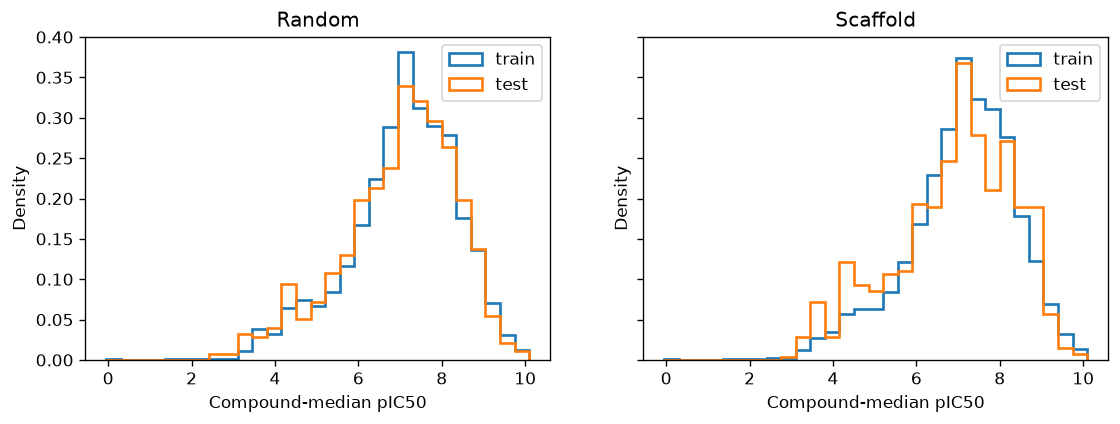

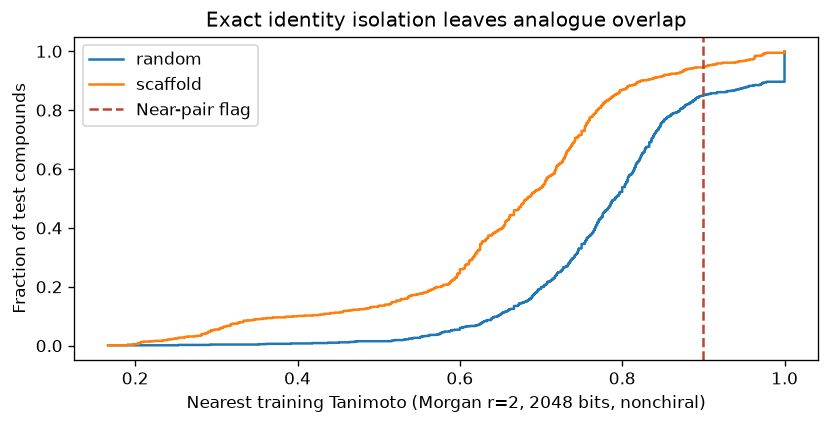

In [6]:
audit = split_target(RAW, CURATED, SPLITS)
assignments = {name: pd.read_csv(SPLITS / f"{name}_assignments.csv", keep_default_na=False)
               for name in ("random", "scaffold")}
structure_rows = []
for name, frame in assignments.items():
    train = frame.loc[frame.partition == "train"]
    test = frame.loc[frame.partition == "test"]
    assert set(train.inchikey).isdisjoint(test.inchikey), f"Identity leakage in {name}"
    if name == "scaffold":
        assert set(train.scaffold).isdisjoint(test.scaffold), "Scaffold leakage"
    summary = audit["splits"][name]
    for side in ("train", "test"):
        structure_rows.append({"Split": name, "Partition": side, **summary[side],
                               "pIC50": json.dumps(summary[side]["pIC50"])})
display(pd.DataFrame(structure_rows).set_index(["Split", "Partition"]))
display(pd.DataFrame({name: {key: audit["splits"][name][key] for key in (
    "inchikey_overlap", "shared_scaffolds", "shared_connectivity_keys",
    "test_compounds_with_train_scaffold", "test_compounds_with_near_duplicate",
    "test_compounds_outside_train_pIC50_range"
)} for name in assignments}))
fig = new_figure(figsize=(11, 3.5))
axes = fig.subplots(1, 2, sharex=True, sharey=True)
bins = np.linspace(compounds.pIC50_median.min(), compounds.pIC50_median.max(), 30)
for ax, (name, frame) in zip(axes, assignments.items()):
    for side in ("train", "test"):
        ax.hist(frame.loc[frame.partition == side, "pIC50_median"], bins=bins,
                density=True, histtype="step", linewidth=1.6, label=side)
    ax.set(title=name.capitalize(), xlabel="Compound-median pIC50", ylabel="Density")
    ax.legend()
show_figure(fig)
fig = new_figure(figsize=(8, 3.5))
ax = fig.subplots()
for name in assignments:
    nearest = pd.read_csv(SPLITS / f"{name}_nearest_train.csv").tanimoto.sort_values().to_numpy()
    ax.step(nearest, np.arange(1, len(nearest) + 1) / len(nearest), where="post", label=name)
ax.axvline(audit["near_duplicate_threshold"], color="#b74735", linestyle="--", label="Near-pair flag")
ax.set(xlabel="Nearest training Tanimoto (Morgan r=2, 2048 bits, nonchiral)",
       ylabel="Fraction of test compounds", title="Exact identity isolation leaves analogue overlap")
ax.legend()
show_figure(fig)

## One fixed leakage probe; no search or tuning

The probe stores training fingerprints and labels. It predicts using maximum
Tanimoto similarity, averaging all tied nearest labels. Fingerprints, rule and seed
are identical in both splits. Compound medians enter once, without repeat weighting.
95% intervals resample **whole held-out scaffold groups**, with training/predictions
fixed. They exclude split-seed and retraining variability; cross-core similarity can
couple groups. Overlapping intervals are not a significance test of the difference.

# Gate 2 fixed leakage probe (not a baseline)

Command: `.venv/bin/python -m src.leakage_probe CHEMBL284`.

Fixed Tanimoto 1-nearest-neighbour leakage probe (not a baseline)

Training pIC50_median at maximum Tanimoto; average all exact maximum ties. Store training fingerprints and compound-median labels only; no tuning.
Features: nonchiral Morgan radius 2, 2048 bits; identical for both saved splits. All compounds carry equal weight after median aggregation. No parameter or split search.

| Metric (95% interval) | Random | Scaffold |
|---|---:|---:|
| RMSE | 0.970 [0.857, 1.088] | 1.129 [0.950, 1.308] |
| MAE | 0.618 [0.558, 0.677] | 0.777 [0.654, 0.919] |
| R2 | 0.505 [0.381, 0.610] | 0.390 [0.105, 0.585] |

RMSE and MAE are pIC50 log units; R2 is dimensionless.

95% percentile bootstrap, 2000 resamples of whole test exact-scaffold groups, compound-weighted metrics; fixed training set, split and predictions. Not uncertainty across split seeds or retraining. Cross-core similarity can still couple groups. Intervals are descriptive, not a significance test of the gap.
Test bootstrap groups: 472 random and 341 scaffold. Seed 42.

## What this dataset lets the probe reuse

Random holds out 793 compounds, but 582 already have a training core (268 shared cores); 120 have a training neighbour at Tanimoto >=0.90. Scaffold holds out 802 compounds with zero shared cores, yet retains 44 such close-neighbour compounds. A stored analogue's label can therefore interpolate a familiar series under random allocation. Exact InChIKey isolation alone does not prevent this structural information reuse.

Largest exact-core groups (canonical scaffold strings and sizes are in probe.json): 133 compounds (26 random-test), 66 compounds (16 random-test), 60 compounds (10 random-test), 52 compounds (4 random-test), 40 compounds (7 random-test).

Observed scaffold-minus-random RMSE: +0.159 log units. The contrast measures this probe's sensitivity to the evaluation boundary. It does not isolate a causal leakage penalty: the test compounds and activity distributions also differ. No held-out labels affected features, assignments, predictions or parameter choices.

| Split / diagnostic subgroup | Test compounds | RMSE |
|---|---:|---:|
| random: shared_train_scaffold=True | 582 | 0.921 |
| random: shared_train_scaffold=False | 211 | 1.093 |
| random: near_train_neighbour=True | 120 | 0.819 |
| random: near_train_neighbour=False | 673 | 0.994 |
| scaffold: shared_train_scaffold=True | 0 | undefined |
| scaffold: shared_train_scaffold=False | 802 | 1.129 |
| scaffold: near_train_neighbour=True | 44 | 1.161 |
| scaffold: near_train_neighbour=False | 758 | 1.127 |

Subgroups explain the boundary; they were not used to tune or exclude compounds. They differ in chemistry and size and are not controlled experiments. Close neighbours need not agree in measured activity; compare their errors above rather than assuming similarity guarantees reliable prediction.

Over-reported compounds cannot leak identical rows here: one median label per standardised InChIKey enters each split, and exact overlap is asserted zero. Training-side repeat rows collapsed before fitting: 723 random / 689 scaffold. The probe never weights those rows. Scaffold holdout also removes shared connectivity keys; residual fingerprint similarity can reflect related cores, stereochemistry ignored by the fingerprint, or bit collisions.

These intervals do not turn conditional replicate dispersion into a universal RMSE floor. The predicted targets are compound medians, whereas replicate SD describes individual reported measurements on a selected repeated subset. A lower RMSE alone cannot establish leakage.

Literature/patent-reported IC50; no efficacy, safety or suitability claim.


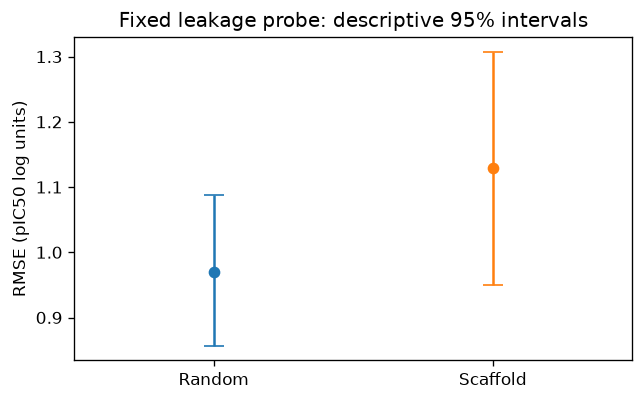

In [7]:
probe = run_probe(RAW, CURATED, SPLITS, PROBE)
display(Markdown((PROBE / "probe.md").read_text()))
fig = new_figure(figsize=(6, 3.5))
ax = fig.subplots()
for index, name in enumerate(assignments):
    result = probe["splits"][name]
    point = result["metrics"]["rmse"]
    bounds = result["bootstrap"]["metrics"]["rmse"]["ci95"]
    ax.errorbar(index, point, yerr=[[point - bounds[0]], [bounds[1] - point]],
                fmt="o", capsize=6, label=name)
ax.set(xticks=[0, 1], xticklabels=["Random", "Scaffold"], xlim=(-.5, 1.5),
       ylabel="RMSE (pIC50 log units)", title="Fixed leakage probe: descriptive 95% intervals")
show_figure(fig)

## Reproducibility checks and stopping point

The generated compound/record CSVs, split assignments, similarities and predictions
must match the committed artifacts byte for byte. Numerical summaries and bootstrap
intervals must also match. Curation timestamps and derived manifest hashes can change
with a rerun; these are provenance fields rather than prediction differences.

The random/scaffold contrast demonstrates sensitivity to the evaluation boundary.
Its gap is not a controlled causal estimate of leakage: held-out chemistry and labels
differ too. Scaffold holdout leaves residual close analogues. Exact row memorisation
is prevented by aggregation and zero full-InChIKey overlap. No result licenses an
efficacy, safety or suitability claim. **Stop at Gate 2.** Final curation narrative,
noise-reference review and room sign-off remain separate review tasks.

In [8]:
for name in ("compounds.csv", "records_curated.csv"):
    assert (CURATED / name).read_bytes() == (ROOT / "data/curated/CHEMBL284" / name).read_bytes(), name
for generated, saved in ((SPLITS, ROOT / "results/splits/CHEMBL284"),
                         (PROBE, ROOT / "results/leakage_probe/CHEMBL284")):
    for path in generated.glob("*.csv"):
        assert path.read_bytes() == (saved / path.name).read_bytes(), path.name
saved_curation = json.loads((ROOT / "results/curation/CHEMBL284/curation_log.json").read_text())
for key in ("steps", "target_variable", "replicate_noise", "identity_decisions", "censoring_reconciliation"):
    assert json.loads(json.dumps(curation[key], default=str)) == saved_curation[key], key
saved_audit = json.loads((ROOT / "results/splits/CHEMBL284/audit.json").read_text())
saved_probe = json.loads((ROOT / "results/leakage_probe/CHEMBL284/probe.json").read_text())
assert audit["splits"] == saved_audit["splits"]
assert probe["splits"] == saved_probe["splits"]
assert probe["rmse_gap_scaffold_minus_random"] == saved_probe["rmse_gap_scaffold_minus_random"]
assert verify_raw(RAW) and raw_hashes() == raw_before, "Raw files changed"
workspace.cleanup()
print("PASS: complete offline rerun matches committed data, split audits, predictions and uncertainty.")
print("PASS: all raw files, including the raw manifest, are unchanged.")

PASS: complete offline rerun matches committed data, split audits, predictions and uncertainty.
PASS: all raw files, including the raw manifest, are unchanged.
